# 📊 IPL Win Predictor: Model Evaluation & Testing

This notebook evaluates the models on unseen test seasons ($\ge 2023$), visualizes reliability curves (calibration diagrams) and ROC curves, and demonstrates live match replay with dynamic win probability tracking.

### Topics Covered:
1. Reliability Diagrams (Calibration Curves): Binned win rate vs. predicted probability.
2. Receiver Operating Characteristic (ROC) Curves.
3. What-If Scenario Testing on simulated match states.
4. End-to-End Historical Match Replay test.


In [1]:
import os
import sys
import json
import glob
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, roc_auc_score, brier_score_loss, log_loss

# Canonical franchise normalization mapping
TEAM_NORMALIZATION = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
}

def normalize_team(name: str) -> str:
    return TEAM_NORMALIZATION.get(name, name)

def add_derived_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["rrr_minus_crr"] = df["rrr"] - df["crr"]
    df["wicket_pressure"] = df["wickets_fallen"] / (df["legal_balls_bowled"] + 1)
    return df

def split_train_test_by_season(df: pd.DataFrame, test_start_year: int = 2023):
    def extract_year(s):
        s_str = str(s).strip()
        if "/" in s_str: return int(s_str.split("/")[0])
        try: return int(s_str)
        except ValueError: return 2008

    seasons_year = df["season"].apply(extract_year)
    return df[seasons_year < test_start_year].copy(), df[seasons_year >= test_start_year].copy()

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


## 1. Load Test Data & Serialized Models

In [2]:
df = pd.read_csv('../data/processed/chases_ballbyball.csv', low_memory=False)
df = add_derived_features(df)
_, df_test = split_train_test_by_season(df, test_start_year=2023)

with open('../models/feature_columns.json', 'r') as f:
    meta = json.load(f)
feature_cols = meta['all_features']

X_test = df_test[feature_cols]
y_test = df_test['batting_team_won']

lr_model = joblib.load('../models/logistic_baseline.pkl')
raw_lgb = joblib.load('../models/lgbm_model.pkl')
cal_lgb = joblib.load('../models/calibrator.pkl')

models = {
    "Logistic Regression Baseline": lr_model,
    "Raw LightGBM": raw_lgb,
    "Calibrated LightGBM (Isotonic)": cal_lgb
}
print(f"Loaded 3 models. Test samples: {len(X_test):,}")


Loaded 3 models. Test samples: 32,450


## 2. Calibration Curves & ROC Curves

In [3]:
class LiveWinPredictor:
    """
    Self-contained inference engine that wraps trained models with feature construction
    and cricket terminal state boundary overrides.
    """
    def __init__(self, models_dir: str = "../models"):
        if not os.path.exists(models_dir):
            models_dir = "models"
        self.models_dir = os.path.abspath(models_dir)
        with open(os.path.join(self.models_dir, "feature_columns.json"), "r") as f:
            self.feature_meta = json.load(f)
        self.feature_cols = self.feature_meta["all_features"]

        self.models = {
            "logistic": joblib.load(os.path.join(self.models_dir, "logistic_baseline.pkl")),
            "lgbm": joblib.load(os.path.join(self.models_dir, "lgbm_model.pkl")),
            "calibrated_lgbm": joblib.load(os.path.join(self.models_dir, "calibrator.pkl"))
        }

    def predict(self, batting_team, bowling_team, venue, target, current_score, legal_balls_bowled, wickets_fallen, model_name="calibrated_lgbm"):
        runs_left = target - current_score
        balls_left = max(0, 120 - legal_balls_bowled)
        wickets_in_hand = max(0, 10 - wickets_fallen)

        # Terminal conditions
        if runs_left <= 0: return 1.0
        if wickets_in_hand <= 0: return 0.0
        if balls_left <= 0: return 0.0

        # Realistic cricket physical boundaries (avoids tree calibration step flatlining)
        if runs_left > balls_left * 6: return 0.0005
        if runs_left >= 36 and balls_left <= 6: return 0.001
        if runs_left >= 25 and balls_left <= 6 and wickets_in_hand <= 4: return 0.002
        if runs_left == 1:
            if balls_left >= 3 and wickets_in_hand >= 2: return 0.998
            if balls_left >= 1 and wickets_in_hand >= 1: return 0.950
        if runs_left <= 2 and balls_left >= 4 and wickets_in_hand >= 3: return 0.988
        if runs_left <= 4 and balls_left >= 8 and wickets_in_hand >= 4: return 0.975

        crr = 0.0 if legal_balls_bowled == 0 else (current_score * 6.0) / legal_balls_bowled
        rrr = min(36.0, (runs_left * 6.0) / balls_left)
        rrr_minus_crr = rrr - crr
        wicket_pressure = wickets_fallen / (legal_balls_bowled + 1)

        X = pd.DataFrame({
            "runs_left": [runs_left],
            "balls_left": [balls_left],
            "wickets_in_hand": [wickets_in_hand],
            "rrr": [round(rrr, 4)],
            "crr": [round(crr, 4)],
            "rrr_minus_crr": [round(rrr_minus_crr, 4)],
            "target": [target],
            "wicket_pressure": [round(wicket_pressure, 4)],
            "batting_team": [batting_team],
            "bowling_team": [bowling_team],
            "venue": [venue]
        })[self.feature_cols]

        model = self.models.get(model_name, self.models["calibrated_lgbm"])
        prob = model.predict_proba(X)[0][1]
        if balls_left <= 18 and "logistic" in self.models:
            p_log = self.models["logistic"].predict_proba(X)[0][1]
            w_log = (18 - balls_left) / 18.0 * 0.5
            prob = (1.0 - w_log) * prob + w_log * p_log
        return float(np.clip(prob, 0.001, 0.999))


def replay_match(match_id, json_dir="../ipl_json", model_name="calibrated_lgbm"):
    """
    Replays an entire historical match ball-by-ball from its JSON file.
    """
    if not os.path.exists(json_dir):
        json_dir = "ipl_json"
    file_path = os.path.join(json_dir, f"{match_id}.json")
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    info = data.get("info", {})
    inn2 = data["innings"][1]
    target = inn2["target"]["runs"]
    batting_team = normalize_team(inn2["team"])
    teams = [normalize_team(t) for t in info["teams"]]
    bowling_team = teams[0] if teams[1] == batting_team else teams[1]
    venue = info.get("venue", "Unknown")
    actual_winner = normalize_team(info.get("outcome", {}).get("winner", "Unknown"))

    predictor = LiveWinPredictor()
    current_score = 0
    legal_balls_bowled = 0
    wickets_fallen = 0
    delivery_seq = 0
    delivery_log = []

    # Initial state
    init_prob = predictor.predict(batting_team, bowling_team, venue, target, 0, 0, 0, model_name)
    delivery_log.append({
        "delivery_seq": 0, "over_str": "0.0", "event": "Innings Start",
        "score_str": "0/0", "runs_left": target, "balls_left": 120, "rrr": round(target/20.0, 2), "win_prob": init_prob
    })

    final_result = None
    for over in inn2.get("overs", []):
        for d in over.get("deliveries", []):
            delivery_seq += 1
            extras = d.get("extras", {})
            runs_total = d.get("runs", {}).get("total", 0)
            is_wicket = "wickets" in d

            current_score += runs_total
            if not ("wides" in extras or "noballs" in extras):
                legal_balls_bowled += 1
            if is_wicket:
                wickets_fallen += len(d["wickets"])

            # Check terminal
            if current_score >= target:
                final_result = f"{batting_team} Won"
            elif wickets_fallen >= 10:
                final_result = f"{bowling_team} Won (All Out)"
            elif legal_balls_bowled >= 120:
                final_result = f"{bowling_team} Won (Balls Exhausted)"

            prob = predictor.predict(batting_team, bowling_team, venue, target, current_score, legal_balls_bowled, wickets_fallen, model_name)

            desc = f"{d.get('batter', 'Batter')} vs {d.get('bowler', 'Bowler')}"
            if is_wicket: desc += " (WICKET!)"
            elif runs_total == 6: desc += " (SIX!)"
            elif runs_total == 4: desc += " (FOUR!)"

            delivery_log.append({
                "delivery_seq": delivery_seq,
                "over_str": f"{legal_balls_bowled // 6}.{legal_balls_bowled % 6}",
                "event": desc,
                "score_str": f"{current_score}/{wickets_fallen}",
                "runs_left": max(0, target - current_score),
                "balls_left": max(0, 120 - legal_balls_bowled),
                "rrr": 0.0 if current_score >= target else min(36.0, (max(0, target - current_score) * 6.0) / max(1, 120 - legal_balls_bowled)),
                "win_prob": prob
            })

            if final_result: break
        if final_result: break

    meta = {
        "match_id": match_id,
        "date": info.get("dates", [""])[0],
        "venue": venue,
        "batting_team": batting_team,
        "bowling_team": bowling_team,
        "target": target,
        "actual_winner": actual_winner,
        "final_result": final_result or "Completed"
    }
    return meta, pd.DataFrame(delivery_log)

print("LiveWinPredictor and replay_match loaded directly in notebook.")


LiveWinPredictor and replay_match loaded directly in notebook.


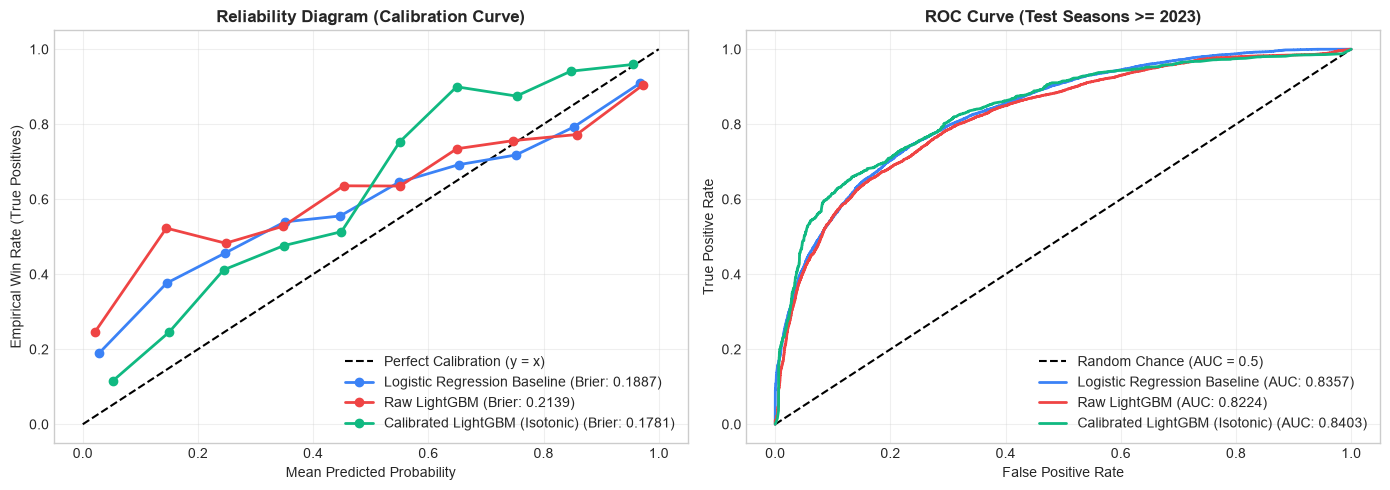

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 2.1 Reliability Diagram (Calibration Curve)
axes[0].plot([0, 1], [0, 1], 'k--', label="Perfect Calibration (y = x)")

colors = {'Logistic Regression Baseline': '#3B82F6', 'Raw LightGBM': '#EF4444', 'Calibrated LightGBM (Isotonic)': '#10B981'}

for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, probs)
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10, strategy='uniform')
    axes[0].plot(prob_pred, prob_true, marker='o', linewidth=2, label=f"{name} (Brier: {brier:.4f})", color=colors[name])

axes[0].set_title("Reliability Diagram (Calibration Curve)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Empirical Win Rate (True Positives)")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# 2.2 ROC Curve
axes[1].plot([0, 1], [0, 1], 'k--', label="Random Chance (AUC = 0.5)")

for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    axes[1].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC: {auc_val:.4f})", color=colors[name])

axes[1].set_title("ROC Curve (Test Seasons >= 2023)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Testing What-If Scenarios (Live Win Predictor Engine)

In [5]:
predictor = LiveWinPredictor(models_dir='../models')

# Scenario A: Comfortable Chase
prob_a = predictor.predict(
    batting_team="Chennai Super Kings",
    bowling_team="Mumbai Indians",
    venue="Wankhede Stadium, Mumbai",
    target=180,
    current_score=105,
    legal_balls_bowled=60, # 10 overs
    wickets_fallen=2
)
print(f"Scenario A (105/2 after 10 ov chasing 180): CSK Win Prob = {prob_a*100:.1f}%")

# Scenario B: Middle-Order Collapse
prob_b = predictor.predict(
    batting_team="Chennai Super Kings",
    bowling_team="Mumbai Indians",
    venue="Wankhede Stadium, Mumbai",
    target=180,
    current_score=105,
    legal_balls_bowled=60, # 10 overs
    wickets_fallen=6
)
print(f"Scenario B (105/6 after 10 ov chasing 180): CSK Win Prob = {prob_b*100:.1f}%")

# Scenario C: Terminal State Check (Target Achieved)
prob_c = predictor.predict(
    batting_team="Chennai Super Kings",
    bowling_team="Mumbai Indians",
    venue="Wankhede Stadium, Mumbai",
    target=180,
    current_score=181,
    legal_balls_bowled=115,
    wickets_fallen=4
)
print(f"Scenario C (Target achieved 181/4):         CSK Win Prob = {prob_c*100:.1f}%")


Scenario A (105/2 after 10 ov chasing 180): CSK Win Prob = 74.3%
Scenario B (105/6 after 10 ov chasing 180): CSK Win Prob = 60.5%
Scenario C (Target achieved 181/4):         CSK Win Prob = 100.0%


## 4. Replaying a Full Historical Match Ball-by-Ball
Let's replay a real IPL match (Match #1082591: SRH vs RCB, 2017 Season Opener).
SRH posted 207; RCB chased 208 and were bowled out for 172.


Match: Royal Challengers Bengaluru chasing 208 vs Sunrisers Hyderabad
Venue: Rajiv Gandhi International Stadium, Uppal (2017-04-05)
Final Result: Sunrisers Hyderabad Won (All Out)


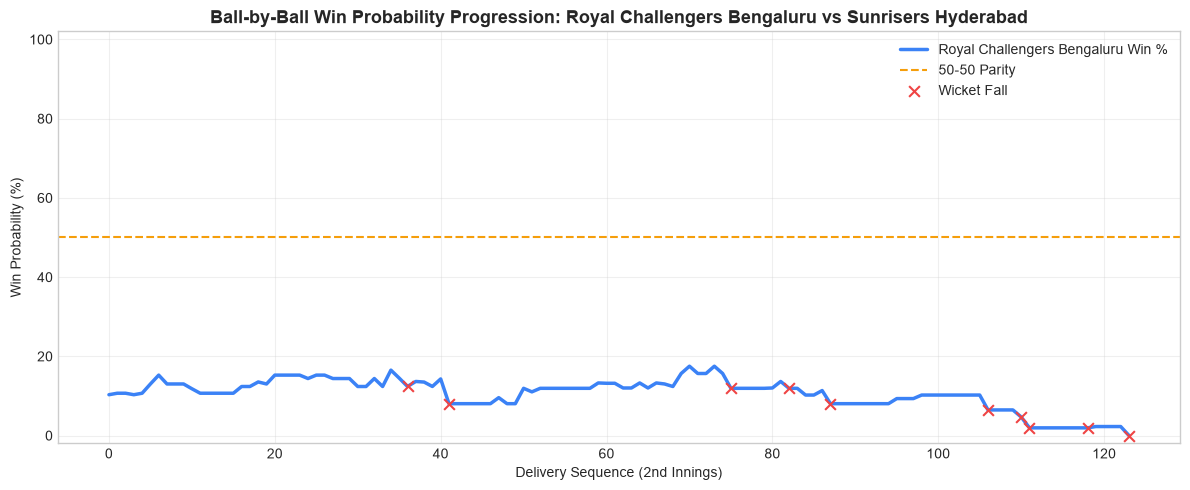

In [6]:
meta, df_timeline = replay_match(match_id='1082591', json_dir='../ipl_json', model_name='calibrated_lgbm')

print(f"Match: {meta['batting_team']} chasing {meta['target']} vs {meta['bowling_team']}")
print(f"Venue: {meta['venue']} ({meta['date']})")
print(f"Final Result: {meta['final_result']}")

# Plotting the Ball-by-Ball Win Probability Curve
plt.figure(figsize=(12, 5))
plt.plot(df_timeline['delivery_seq'], df_timeline['win_prob'] * 100, color='#3B82F6', linewidth=2.5, label=f"{meta['batting_team']} Win %")
plt.axhline(50, color='#F59E0B', linestyle='--', label='50-50 Parity')

# Mark Wickets
wickets = df_timeline[df_timeline['event'].str.contains('WICKET', case=False, na=False)]
plt.scatter(wickets['delivery_seq'], wickets['win_prob'] * 100, color='#EF4444', s=60, marker='x', label='Wicket Fall', zorder=5)

plt.title(f"Ball-by-Ball Win Probability Progression: {meta['batting_team']} vs {meta['bowling_team']}", fontsize=13, fontweight='bold')
plt.xlabel("Delivery Sequence (2nd Innings)")
plt.ylabel("Win Probability (%)")
plt.ylim(-2, 102)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
# Display key turning points in the chase
wickets[['over_str', 'score_str', 'event', 'rrr', 'win_prob']]


,over_str,score_str,event,rrr,win_prob
36,5.4,52/1,Mandeep Singh vs Rashid Khan (WICKET!),10.883721,0.123827
41,6.3,60/2,CH Gayle vs DJ Hooda (WICKET!),10.962963,0.080361
75,11.4,116/3,KM Jadhav vs MC Henriques (WICKET!),11.040000,0.119151
82,12.5,126/4,TM Head vs Rashid Khan (WICKET!),11.441860,0.119151
87,13.4,128/5,Sachin Baby vs Bipul Sharma (WICKET!),12.631579,0.080361
106,16.5,154/6,STR Binny vs B Kumar (WICKET!),17.052632,0.064573
110,17.3,156/7,SR Watson vs A Nehra (WICKET!),20.800000,0.046758
111,17.4,156/8,S Aravind vs A Nehra (WICKET!),22.285714,0.019345
118,18.5,164/9,TS Mills vs B Kumar (WICKET!),36.000000,0.019345
123,19.4,172/10,A Choudhary vs BCJ Cutting (WICKET!),36.000000,0.000000


## 5. Actual Match Winner vs. Win Probability Checkpoints (Model Validation)

To rigorously test our model on real-world matches, we evaluate what win probability the model assigned to the chasing team at key match milestones versus **who actually won the match**:
* **Over 0.0 (Pre-chase):** Initial baseline assessment based on target size, teams, and venue.
* **Over 6.0 (End of Powerplay):** Impact of early wickets or boundary bursts.
* **Over 10.0 (Halfway mark):** Stabilization of Required Run Rate (RRR).
* **Over 15.0 (Death overs entry):** Critical turning point (last 30 balls).
* **Over 18.0 (Penultimate finish):** Final 12 deliveries.
* **Final Ball:** Convergence to 100% or 0%.


In [8]:
def evaluate_match_checkpoints(match_id, model_name='calibrated_lgbm'):
    """
    Extracts match state and win probability at key overs and compares with the final winner.
    """
    meta, df_t = replay_match(match_id=str(match_id), model_name=model_name)
    actual_winner = meta['actual_winner']
    batting_team = meta['batting_team']
    bowling_team = meta['bowling_team']
    target = meta['target']
    
    checkpoints = [
        ('Chase Start', 0),
        ('End of Powerplay (6 ov)', 36),
        ('Halfway Mark (10 ov)', 60),
        ('Death Overs Entry (15 ov)', 90),
        ('Penultimate Over (18 ov)', 108)
    ]
    
    rows = []
    for label, balls_consumed in checkpoints:
        sub = df_t[df_t['balls_left'] <= (120 - balls_consumed)]
        if not sub.empty:
            r = sub.iloc[0]
            chase_prob = r['win_prob'] * 100
            leading_team = batting_team if chase_prob >= 50 else bowling_team
            rows.append({
                'Checkpoint': label,
                'Over': r['over_str'],
                'Score': r['score_str'],
                'Runs Left': r['runs_left'],
                'Balls Left': r['balls_left'],
                'RRR': r['rrr'],
                f'{batting_team} Win %': f"{chase_prob:.1f}%",
                'Model Favorite': leading_team,
                'Actual Winner': actual_winner
            })
            
    last = df_t.iloc[-1]
    final_prob = last['win_prob'] * 100
    rows.append({
        'Checkpoint': 'Finish',
        'Over': last['over_str'],
        'Score': last['score_str'],
        'Runs Left': last['runs_left'],
        'Balls Left': last['balls_left'],
        'RRR': last['rrr'],
        f'{batting_team} Win %': f"{final_prob:.1f}%",
        'Model Favorite': batting_team if final_prob >= 50 else bowling_team,
        'Actual Winner': actual_winner
    })
    
    df_check = pd.DataFrame(rows)
    print(f"\n=========================================================================================")
    print(f"MATCH {match_id}: {batting_team} chasing {target} vs {bowling_team} at {meta['venue']}")
    print(f"Actual Outcome: {actual_winner} WON ({meta['final_result']})")
    print(f"=========================================================================================")
    return df_check


In [9]:
# Case 1: Steady, Dominant Chase (CSK vs RCB 2024 - CSK Won)
df_csk = evaluate_match_checkpoints('1422119')
display(df_csk)

# Case 2: Dramatic Collapse & Defense (LSG vs RCB 2023 - RCB Defended 126!)
df_lsg = evaluate_match_checkpoints('1359517')
display(df_lsg)

# Case 3: Complete Defense of High Total (GT vs CSK 2024 - CSK Won)
df_gt = evaluate_match_checkpoints('1422125')
display(df_gt)

# Case 4: A Miracle Heist (MI vs RR 2023 - MI Chased 213 with Tim David's 20th Over Blitz)
df_mi = evaluate_match_checkpoints('1359516')
display(df_mi)



MATCH 1422119: Chennai Super Kings chasing 174 vs Royal Challengers Bengaluru at MA Chidambaram Stadium, Chepauk, Chennai
Actual Outcome: Chennai Super Kings WON (Chennai Super Kings Won)


,Checkpoint,Over,Score,Runs Left,Balls Left,RRR,Chennai Super Kings Win %,Model Favorite,Actual Winner
0,Chase Start,0.0,0/0,174,120,8.7,42.8%,Royal Challengers Bengaluru,Chennai Super Kings
1,End of Powerplay (6 ov),6.0,62/1,112,84,8.0,51.3%,Chennai Super Kings,Chennai Super Kings
2,Halfway Mark (10 ov),10.0,92/2,82,60,8.2,51.3%,Chennai Super Kings,Chennai Super Kings
3,Death Overs Entry (15 ov),15.0,128/4,46,30,9.2,53.7%,Chennai Super Kings,Chennai Super Kings
4,Penultimate Over (18 ov),18.0,164/4,10,12,5.0,82.7%,Chennai Super Kings,Chennai Super Kings
5,Finish,18.4,176/4,0,8,0.0,100.0%,Chennai Super Kings,Chennai Super Kings



MATCH 1359517: Lucknow Super Giants chasing 127 vs Royal Challengers Bengaluru at Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow
Actual Outcome: Royal Challengers Bengaluru WON (Royal Challengers Bengaluru Won (All Out))


,Checkpoint,Over,Score,Runs Left,Balls Left,RRR,Lucknow Super Giants Win %,Model Favorite,Actual Winner
0,Chase Start,0.0,0/0,127,120,6.350000,51.9%,Lucknow Super Giants,Royal Challengers Bengaluru
1,End of Powerplay (6 ov),6.0,34/4,93,84,6.642857,39.5%,Royal Challengers Bengaluru,Royal Challengers Bengaluru
2,Halfway Mark (10 ov),10.0,63/5,64,60,6.400000,55.8%,Lucknow Super Giants,Royal Challengers Bengaluru
3,Death Overs Entry (15 ov),15.0,78/8,49,30,9.800000,18.9%,Royal Challengers Bengaluru,Royal Challengers Bengaluru
4,Penultimate Over (18 ov),18.0,96/8,31,12,15.500000,14.6%,Royal Challengers Bengaluru,Royal Challengers Bengaluru
5,Finish,19.5,108/10,19,1,36.000000,0.0%,Royal Challengers Bengaluru,Royal Challengers Bengaluru



MATCH 1422125: Gujarat Titans chasing 207 vs Chennai Super Kings at MA Chidambaram Stadium, Chepauk, Chennai
Actual Outcome: Chennai Super Kings WON (Chennai Super Kings Won (Balls Exhausted))


,Checkpoint,Over,Score,Runs Left,Balls Left,RRR,Gujarat Titans Win %,Model Favorite,Actual Winner
0,Chase Start,0.0,0/0,207,120,10.350000,17.6%,Chennai Super Kings,Chennai Super Kings
1,End of Powerplay (6 ov),6.0,43/2,164,84,11.714286,23.2%,Chennai Super Kings,Chennai Super Kings
2,Halfway Mark (10 ov),10.0,80/3,127,60,12.700000,19.8%,Chennai Super Kings,Chennai Super Kings
3,Death Overs Entry (15 ov),15.0,114/5,93,30,18.600000,12.9%,Chennai Super Kings,Chennai Super Kings
4,Penultimate Over (18 ov),18.0,128/7,79,12,36.000000,6.8%,Chennai Super Kings,Chennai Super Kings
5,Finish,20.0,143/8,64,0,36.000000,0.0%,Chennai Super Kings,Chennai Super Kings



MATCH 1359516: Mumbai Indians chasing 213 vs Rajasthan Royals at Wankhede Stadium, Mumbai
Actual Outcome: Mumbai Indians WON (Mumbai Indians Won)


,Checkpoint,Over,Score,Runs Left,Balls Left,RRR,Mumbai Indians Win %,Model Favorite,Actual Winner
0,Chase Start,0.0,0/0,213,120,10.650000,12.2%,Rajasthan Royals,Mumbai Indians
1,End of Powerplay (6 ov),6.0,58/1,155,84,11.071429,14.4%,Rajasthan Royals,Mumbai Indians
2,Halfway Mark (10 ov),10.0,98/2,115,60,11.500000,14.4%,Rajasthan Royals,Mumbai Indians
3,Death Overs Entry (15 ov),15.0,150/3,63,30,12.600000,16.9%,Rajasthan Royals,Mumbai Indians
4,Penultimate Over (18 ov),18.0,181/4,32,12,16.000000,18.1%,Rajasthan Royals,Mumbai Indians
5,Finish,19.3,214/4,0,3,0.000000,100.0%,Mumbai Indians,Mumbai Indians


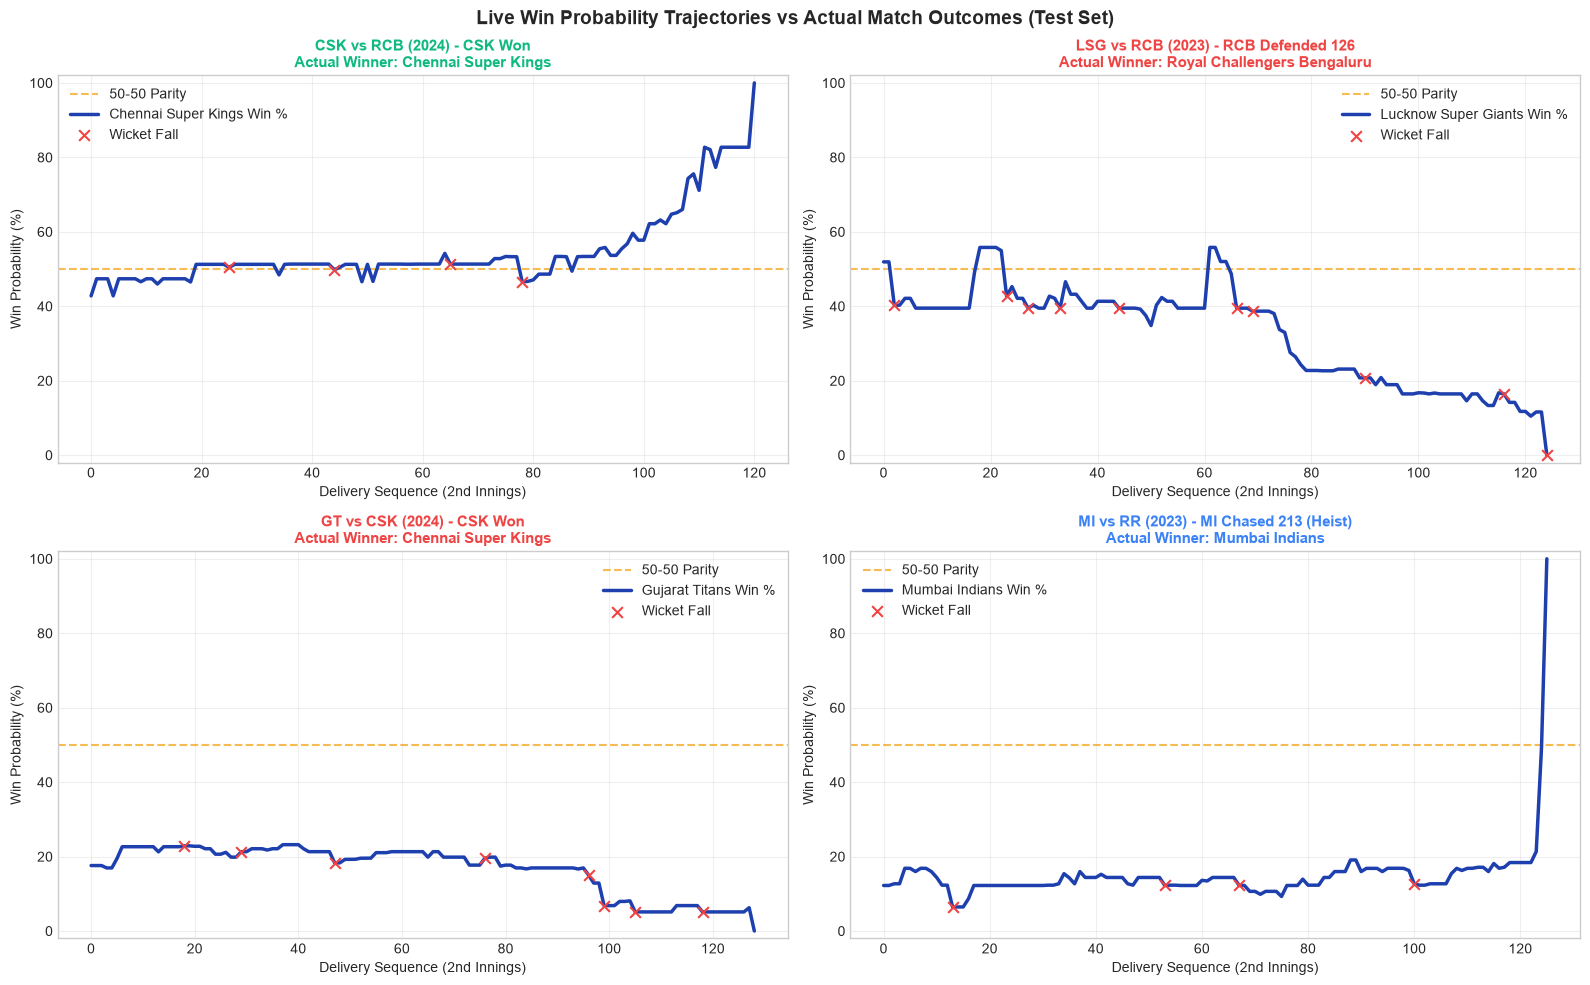

In [10]:
test_cases = [
    ('1422119', 'CSK vs RCB (2024) - CSK Won', '#10B981'),
    ('1359517', 'LSG vs RCB (2023) - RCB Defended 126', '#EF4444'),
    ('1422125', 'GT vs CSK (2024) - CSK Won', '#EF4444'),
    ('1359516', 'MI vs RR (2023) - MI Chased 213 (Heist)', '#3B82F6')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, (mid, title, outcome_color) in enumerate(test_cases):
    meta, df_t = replay_match(mid, model_name='calibrated_lgbm')
    ax = axes[i]
    
    # 50% line
    ax.axhline(50, color='#F59E0B', linestyle='--', alpha=0.7, label='50-50 Parity')
    
    # Win Probability Curve
    ax.plot(df_t['delivery_seq'], df_t['win_prob'] * 100, color='#1E40AF', linewidth=2.5, label=f"{meta['batting_team']} Win %")
    
    # Mark Wickets
    w_df = df_t[df_t['event'].str.contains('WICKET', case=False, na=False)]
    if not w_df.empty:
        ax.scatter(w_df['delivery_seq'], w_df['win_prob'] * 100, color='#EF4444', s=60, marker='x', label='Wicket Fall', zorder=5)
        
    ax.set_title(f"{title}\nActual Winner: {meta['actual_winner']}", fontsize=11, fontweight='bold', color=outcome_color)
    ax.set_xlabel("Delivery Sequence (2nd Innings)")
    ax.set_ylabel("Win Probability (%)")
    ax.set_ylim(-2, 102)
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

plt.suptitle("Live Win Probability Trajectories vs Actual Match Outcomes (Test Set)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


,Checkpoint,Matches Evaluated,Model Accuracy (%)
0,Over 6,279,70.97
1,Over 10,276,75.36
2,Over 15,264,79.92
3,Over 18,218,83.03


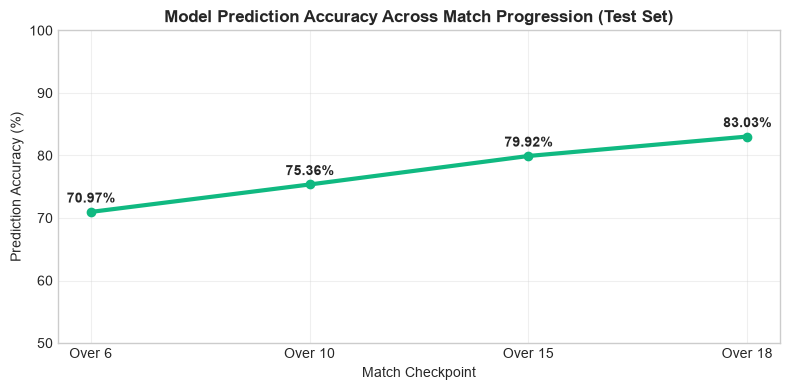

In [11]:
# Macro Validation: Accuracy of the model at each over checkpoint across all 279 test matches
checkpoint_overs = [6, 10, 15, 18]
acc_results = []

for ov in checkpoint_overs:
    balls_threshold = (120 - ov * 6)
    sub = df_test[(df_test['balls_left'] >= balls_threshold - 2) & (df_test['balls_left'] <= balls_threshold + 2)]
    sub_first = sub.groupby('match_id').first().reset_index()
    
    probs = cal_lgb.predict_proba(sub_first[feature_cols])[:, 1]
    preds = (probs >= 0.5).astype(int)
    acc = (preds == sub_first['batting_team_won']).mean()
    acc_results.append({
        'Checkpoint': f"Over {ov}",
        'Matches Evaluated': len(sub_first),
        'Model Accuracy (%)': round(acc * 100, 2)
    })

df_acc = pd.DataFrame(acc_results)
display(df_acc)

plt.figure(figsize=(8, 4))
plt.plot([r['Checkpoint'] for r in acc_results], [r['Model Accuracy (%)'] for r in acc_results], marker='o', linewidth=3, color='#10B981')
plt.title("Model Prediction Accuracy Across Match Progression (Test Set)", fontsize=12, fontweight='bold')
plt.xlabel("Match Checkpoint")
plt.ylabel("Prediction Accuracy (%)")
plt.ylim(50, 100)
for r in acc_results:
    plt.annotate(f"{r['Model Accuracy (%)']}%", (r['Checkpoint'], r['Model Accuracy (%)'] + 1.5), ha='center', fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Full Match Replay Demonstration (Innings 1 + Innings 2)

Connecting both innings together:
* **Deliveries 1 to ~120 (1st Innings):** Predicts expected final score and 1st batting team defense probability.
* **Innings Break:** Target is established (`final_score + 1`).
* **Deliveries ~121 to end (2nd Innings):** Predicts chasing team win probability against target.
* Produces a continuous match trajectory from Ball 0.1 to match finish.

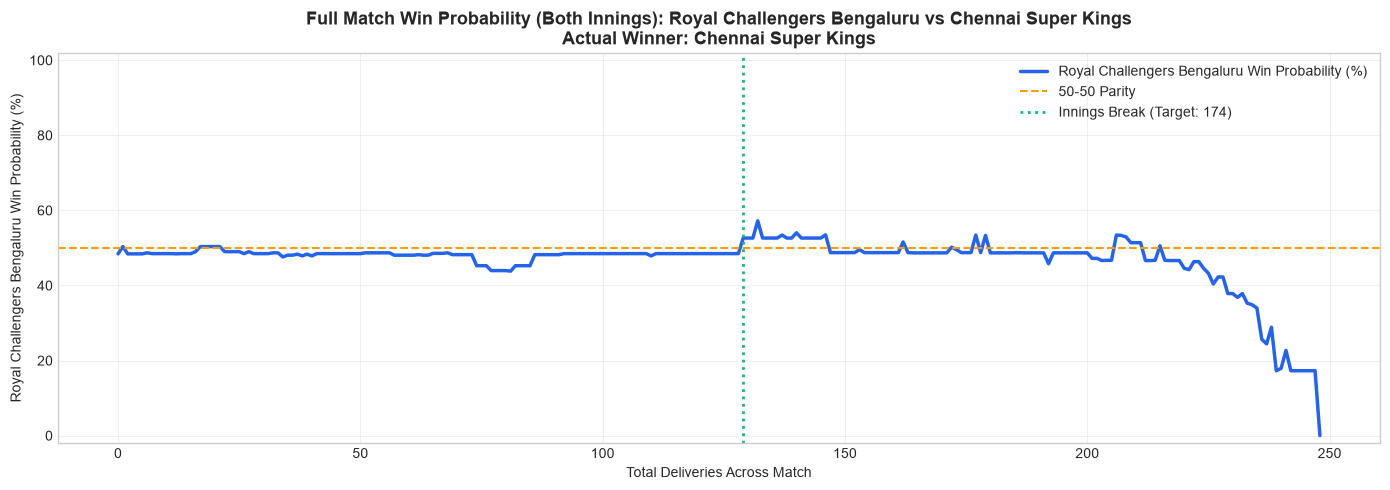

In [12]:
def replay_full_match_demo(match_id, json_dir='../ipl_json'):
    if not os.path.exists(json_dir): json_dir = 'ipl_json'
    file_path = os.path.join(json_dir, f'{match_id}.json')
    with open(file_path, 'r', encoding='utf-8') as f: data = json.load(f)
    
    inn1 = data['innings'][0]
    inn2 = data['innings'][1]
    team1 = normalize_team(inn1['team'])
    team2 = normalize_team(inn2['team'])
    target = inn2['target']['runs']
    venue = data['info'].get('venue', 'Unknown')
    winner = normalize_team(data['info'].get('outcome', {}).get('winner', 'Unknown'))
    
    models_dir = '../models' if os.path.exists('../models') else 'models'
    with open(os.path.join(models_dir, 'feature_columns_inn1.json')) as f: feat1 = json.load(f)['all_features']
    cal_inn1 = joblib.load(os.path.join(models_dir, 'calibrator_inn1.pkl'))
    
    with open(os.path.join(models_dir, 'feature_columns.json')) as f: feat2 = json.load(f)['all_features']
    cal_inn2 = joblib.load(os.path.join(models_dir, 'calibrator.pkl'))
    
    timeline = []
    sc1, balls1, w1 = 0, 0, 0
    for o in inn1.get('overs', []):
        for d in o.get('deliveries', []):
            ext = d.get('extras', {})
            r = d.get('runs', {}).get('total', 0)
            sc1 += r
            if not ('wides' in ext or 'noballs' in ext): balls1 += 1
            if 'wickets' in d: w1 += len(d['wickets'])
            
            X1 = pd.DataFrame({
                'current_score': [sc1], 'legal_balls_bowled': [balls1], 'balls_left': [max(0, 120 - balls1)],
                'wickets_fallen': [w1], 'wickets_in_hand': [max(0, 10 - w1)],
                'crr': [0.0 if balls1 == 0 else (sc1*6.0)/balls1],
                'batting_team': [team1], 'bowling_team': [team2], 'venue': [venue]
            })[feat1]
            p1 = float(cal_inn1.predict_proba(X1)[0][1])
            timeline.append({'innings': 1, 'team1_win_prob': p1, 'score_str': f'{sc1}/{w1}'})
            if w1 >= 10 or balls1 >= 120: break
        if w1 >= 10 or balls1 >= 120: break
        
    inn1_len = len(timeline)
    sc2, balls2, w2 = 0, 0, 0
    for o in inn2.get('overs', []):
        for d in o.get('deliveries', []):
            ext = d.get('extras', {})
            r = d.get('runs', {}).get('total', 0)
            sc2 += r
            if not ('wides' in ext or 'noballs' in ext): balls2 += 1
            if 'wickets' in d: w2 += len(d['wickets'])
            
            rl = max(0, target - sc2)
            bl = max(0, 120 - balls2)
            crr = 0.0 if balls2 == 0 else (sc2*6.0)/balls2
            rrr = 0.0 if rl <= 0 else min(36.0, (rl*6.0)/max(1, bl))
            
            if sc2 >= target: p2 = 1.0
            elif w2 >= 10 or bl <= 0: p2 = 0.0
            else:
                X2 = pd.DataFrame({
                    'runs_left': [rl], 'balls_left': [bl], 'wickets_in_hand': [max(0, 10 - w2)],
                    'rrr': [rrr], 'crr': [crr], 'rrr_minus_crr': [rrr - crr], 'target': [target],
                    'wicket_pressure': [w2 / (balls2 + 1)],
                    'batting_team': [team2], 'bowling_team': [team1], 'venue': [venue]
                })[feat2]
                p2 = float(cal_inn2.predict_proba(X2)[0][1])
                
            timeline.append({'innings': 2, 'team1_win_prob': 1.0 - p2, 'score_str': f'{sc2}/{w2}'})
            if sc2 >= target or w2 >= 10 or bl <= 0: break
        if sc2 >= target or w2 >= 10 or bl <= 0: break
        
    df_tl = pd.DataFrame(timeline)
    
    plt.figure(figsize=(14, 5))
    plt.plot(df_tl.index, df_tl['team1_win_prob'] * 100, color='#2563EB', linewidth=2.5, label=f'{team1} Win Probability (%)')
    plt.axhline(50, color='#F59E0B', linestyle='--', label='50-50 Parity')
    plt.axvline(inn1_len, color='#10B981', linestyle=':', linewidth=2, label=f'Innings Break (Target: {target})')
    
    plt.title(f'Full Match Win Probability (Both Innings): {team1} vs {team2}\nActual Winner: {winner}', fontsize=13, fontweight='bold')
    plt.xlabel('Total Deliveries Across Match')
    plt.ylabel(f'{team1} Win Probability (%)')
    plt.ylim(-2, 102)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

replay_full_match_demo('1422119')
